# 08 · Feature engineering — CICIoT2023 (`IoT23`)
**Owner:** Yassine Mtibaa · **Phase 5 — Feature engineering** · Cross-Network Intrusion Analysis (CRISP-DM)

> *Phase 5 requirement:* explain feature selection, extraction/creation, encoding, and scaling/transformation when appropriate; justify the final feature set.

CICIoT2023 is analysed separately from the merged NetFlow data (different row unit and features, `docs/datasets.md`), so phase 5 is done here
for this dataset. The sections follow the same order as the NetFlow notebook (`08_features_netflow`), so both parts read the same way in the report:

| Section | Content | Board task |
|---|---|---|
| §1 Creation / extraction | time features, packet-size features, domain features — and a check that they work | 5.2, 5.4, 5.5, 5.7 |
| §2 Encoding | one-hot protocol, rare categories grouped | 5.3 |
| §3 Scaling / transformation | log / Yeo-Johnson + RobustScaler, before/after | 5.6, 5.7 |
| §4 Selection | identities, artefacts, near-constant, correlated pairs (\|ρ\| ≥ 0.95), mutual-information ranking | 5.8 |
| §5 Final feature set | table of kept features, export of the dataset and data dictionary | 5.9 |
| §6 PCA | 2-D view of family separability (feature extraction) | 5.10 |
| §7 Techniques not used and why | | |

**Data:** `data/processed/IoT23_clean.parquet` from notebook 05 (cleaned, deduplicated, at most 200,000 rows per attack label).
There is **no train/test split** and no model in this project.

> **Note.** This project has no modelling phase, so every learned step is fitted on all the data. In a modelling phase, these steps must be refitted on the training part only, to avoid data leakage.

In [1]:
import sys; sys.path.append("..")
from src.config import *

import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import RobustScaler, OneHotEncoder, PowerTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 80)

SOURCE = "IoT23"
df = pd.read_parquet(PROCESSED_DIR / f"{SOURCE}_clean.parquet")
for c in ["attack_family", "attack_label"]:
    df[c] = df[c].astype(str)
df["Protocol_Type"] = df["Protocol_Type"].astype(int)

LABEL_COLS = ["Label", "source_dataset", "attack_label", "attack_family", "is_attack", "conflicting_features"]
RAW_FEATURES = [c for c in df.columns if c not in LABEL_COLS]                                # the 39 window features
FLAGS = ["fin_flag_number", "syn_flag_number", "rst_flag_number", "psh_flag_number", "ack_flag_number", "ece_flag_number", "cwr_flag_number"]
APP = ["HTTP", "HTTPS", "DNS", "Telnet", "SMTP", "SSH", "IRC"]
PROTO_SHARES = ["TCP", "UDP", "DHCP", "ARP", "ICMP", "IGMP", "IPv", "LLC"]
COUNTS = ["ack_count", "syn_count", "fin_count", "rst_count"]
SHARES = FLAGS + APP + PROTO_SHARES                                                           # shares of packets in the window, in [0, 1]
CONT_RAW = [c for c in RAW_FEATURES if c not in SHARES + ["Protocol_Type"]]                    # sizes, rates, times, counts
assert len(RAW_FEATURES) == 39 and len(CONT_RAW) + len(SHARES) + 1 == 39

FAMILY_ORDER = [f for f in [BENIGN, "Denial of service", "Malware and botnets", "Reconnaissance",
                            "Interception and spoofing", "Web and injection", "Credential attacks"] if f in set(df["attack_family"])]
PAL = dict(zip(FAMILY_ORDER, sns.color_palette("tab10", len(FAMILY_ORDER))))
PROTO_NAMES = {0: "nonIP", 1: "ICMP", 2: "IGMP", 6: "TCP", 17: "UDP", 47: "GRE"}

# family-balanced sample for plots, mutual information, correlation and PCA (conflicting rows excluded: their label is ambiguous)
BAL = np.concatenate([g.sample(min(len(g), 15_000), random_state=RANDOM_STATE).index
                      for _, g in df[~df["conflicting_features"]].groupby("attack_family")])
yb = df.loc[BAL, "attack_family"]

def savefig(name):
    plt.savefig(FIG_DIR / f"IoT23_fe_{name}.png", dpi=150, bbox_inches="tight"); plt.show()

print(f"{len(df):,} rows | {len(RAW_FEATURES)} raw features: {len(CONT_RAW)} continuous/count, {len(SHARES)} shares, 1 protocol code")
print(f"balanced sample: {len(BAL):,} rows", yb.value_counts().loc[FAMILY_ORDER].to_dict())

4,420,714 rows | 39 raw features: 16 continuous/count, 22 shares, 1 protocol code
balanced sample: 102,503 rows {'Benign': 15000, 'Denial of service': 15000, 'Malware and botnets': 15000, 'Reconnaissance': 15000, 'Interception and spoofing': 15000, 'Web and injection': 15000, 'Credential attacks': 12503}


---
## 1 · Creation / extraction
New columns are built with **row-wise formulas** from the 39 window features. Nothing is learned from the data here.

### 1.1 Time features (5.2)
The task asks for duration, packets per second and bytes per second, and **no hour-of-day** feature.
CICIoT2023 has **no timestamps** at all (notebook 05, 2.1), so a date or hour-of-day feature is not possible — which is what we want anyway,
because it would only learn the lab's attack schedule.

The dataset already has `IAT` (mean time between packets in the window, in seconds) and `Rate` (packets per second). First we check how they are related.

In [2]:
chk = df.sample(300_000, random_state=RANDOM_STATE)
prod = chk["Rate"].astype("float64") * chk["IAT"].astype("float64")
rho_rate_iat = stats.spearmanr(chk["Rate"], chk["IAT"]).statistic
print(f"Rate x IAT: median {prod.median():.4f}, P5 {prod.quantile(.05):.4f}, P95 {prod.quantile(.95):.4f}, "
      f"share within 5 % of 1: {100 * (prod.sub(1).abs() < .05).mean():.1f} % | Spearman rho(Rate, IAT) = {rho_rate_iat:.4f}")

Rate x IAT: median 1.0019, P5 1.0000, P95 1.2968, share within 5 % of 1: 81.6 % | Spearman rho(Rate, IAT) = -0.9953


So `Rate` ≈ 1 / `IAT`: packets per second already exists. The two time features that are missing:

| Feature | Formula | Meaning |
|---|---|---|
| `byte_rate` | `AVG` × `Rate` | bytes per second (mean packet size × packets per second): throughput of the window |
| `window_duration` | `Number` × `IAT` | time spanned by the window, in seconds |

`window_duration` contains `Number` (10 packets for non-flood captures, 100 for floods, a capture artefact found in notebook 07, §6),
so it may inherit the artefact; §4 checks this.

In [3]:
df["byte_rate"] = (df["AVG"].astype("float64") * df["Rate"].astype("float64")).astype("float32")
df["window_duration"] = (df["Number"].astype("float64") * df["IAT"].astype("float64")).astype("float32")
TIME_FEATS = ["byte_rate", "window_duration"]
tf = df.groupby("attack_family")[["Rate", "IAT", "byte_rate", "window_duration", "Number"]].median().loc[FAMILY_ORDER]
tf.to_csv(TABLE_DIR / "IoT23_fe_time_features.csv")
tf.style.format("{:,.4g}")

,Rate,IAT,byte_rate,window_duration,Number
attack_family,,,,,
Benign,170.6,0.006654,5.423e+04,0.06653,10
Denial of service,1.229e+04,8.287e-05,1.255e+06,0.008271,100
Malware and botnets,"4,403",0.0002298,2.507e+06,0.02293,100
Reconnaissance,122,0.009314,1.738e+04,0.09313,10
Interception and spoofing,482.4,0.002355,1.965e+05,0.02354,10
Web and injection,72.51,0.01556,"9,879",0.1556,10
Credential attacks,106.6,0.01043,1.411e+04,0.1042,10


**Interpretation.** `Rate` × `IAT` has a median of 1.0019 (81.6 % of windows within 5 % of 1) and Spearman ρ = −0.995: `Rate` is essentially 1 / `IAT`, so packets per second already exists and only one of the two is needed (§4 keeps `Rate`).

* **`byte_rate`** separates the high-volume families: median 2.507 × 10⁶ B/s for Malware and botnets and 1.255 × 10⁶ for Denial of service, against 5.423 × 10⁴ for Benign and 9,879–1.738 × 10⁴ for web, credential and reconnaissance. The two floods swap places compared with `Rate` (DoS 1.229 × 10⁴ pkt/s vs Mirai 4,403) because Mirai packets are larger: `byte_rate` combines speed *and* size.
* **`window_duration`** is short for the floods (0.0083 s DoS, 0.0229 s Mirai) and 0.06–0.16 s for the others. But `Number` is 100 for both floods and 10 for every other family, so this difference partly measures the window size, not the attack (checked in §4).

### 1.2 Packet-size features (5.4)
The window gives the mean, minimum, maximum and standard deviation of packet sizes. Two combinations describe *how uniform* the packets are,
independently of their absolute size:

| Feature | Formula | Meaning |
|---|---|---|
| `size_range` | `Max` − `Min` | gap between the largest and smallest packet (bytes) |
| `size_cv` | `Std` / `AVG` | coefficient of variation of packet size (no unit): 0 = all packets identical |

(`AVG` is at least 46 bytes, so the division is always defined.)

In [4]:
df["size_range"] = (df["Max"] - df["Min"]).astype("float32")
df["size_cv"] = (df["Std"].astype("float64") / df["AVG"].astype("float64")).astype("float32")
NUM_FEATS = ["size_range", "size_cv"]
df.groupby("attack_family")[NUM_FEATS + ["AVG", "Std"]].median().loc[FAMILY_ORDER].round(3)

,size_range,size_cv,AVG,Std
attack_family,,,,
Benign,1262.0,0.738,249.800003,409.472992
Denial of service,14.0,0.032,60.290001,1.969000
Malware and botnets,467.0,0.084,572.799988,48.000000
Reconnaissance,170.0,0.610,106.599998,67.763000
Interception and spoofing,797.0,0.695,359.299988,328.877014
Web and injection,257.0,0.622,144.199997,86.543999
Credential attacks,170.0,0.614,120.500000,70.833000


**Interpretation.** Packet uniformity splits the families in two groups. Floods send near-identical packets: Denial of service has a median `size_range` of 14 B and `size_cv` of 0.032, Mirai a `size_cv` of 0.084 (range 467 B). All other families have very mixed packets: `size_cv` 0.61–0.74 (Benign 0.738 with a range of 1,262 B, spoofing 0.695 and 797 B, reconnaissance / web / credential 0.61–0.62 and 170–257 B). So these features separate floods from everything else (SQ1), but not the quiet attacks from benign traffic.

### 1.3 Domain features (5.5)
Built from how the attacks work (notebook 07, §6 fingerprints):

| Feature | Formula | Why |
|---|---|---|
| `syn_minus_ack` | `syn_flag_number` − `ack_flag_number` | half-open handshakes: SYN floods send SYNs that are never acknowledged (→ +1), normal TCP traffic is mostly ACKs (→ negative) |
| `app_share` | sum of the 7 application-protocol shares | share of packets from a known application (HTTP, HTTPS, DNS, Telnet, SMTP, SSH, IRC): ≈ 0 for raw floods, high for web, brute-force and normal traffic |
| `control_share` | `syn` + `fin` + `rst` flag shares | connection set-up / tear-down packets: scans and floods are dominated by control packets |

*Traffic asymmetry* (needs the direction of each packet) and *burstiness* (needs the spread of inter-arrival times) cannot be built:
CICIoT2023 has no direction information and only the mean `IAT` of the window.

In [5]:
df["syn_minus_ack"] = (df["syn_flag_number"] - df["ack_flag_number"]).astype("float32")
df["app_share"] = df[APP].sum(axis=1).astype("float32")
df["control_share"] = df[["syn_flag_number", "fin_flag_number", "rst_flag_number"]].sum(axis=1).astype("float32")
DOMAIN_FEATS = ["syn_minus_ack", "app_share", "control_share"]
dom = df.groupby("attack_family")[DOMAIN_FEATS].median().loc[FAMILY_ORDER]
dom.to_csv(TABLE_DIR / "IoT23_fe_domain_features.csv")
dom.round(3)

,syn_minus_ack,app_share,control_share
attack_family,,,
Benign,-0.9,0.9,0.00
Denial of service,0.0,0.0,0.01
Malware and botnets,0.0,0.0,0.00
Reconnaissance,-0.5,0.5,0.10
Interception and spoofing,-0.8,0.8,0.00
Web and injection,-0.6,0.6,0.00
Credential attacks,-0.7,0.7,0.00


**Interpretation.** The quiet attacks sit between benign traffic and the floods. Median `syn_minus_ack` is −0.9 for Benign (mostly ACK packets), −0.8 to −0.5 for spoofing, credential, web and reconnaissance, and 0.0 for Denial of service and Mirai (no handshake). `app_share` mirrors it: 0.9 for Benign, 0.5–0.8 for the quiet attacks, 0.0 for the floods. `control_share` is highest for Reconnaissance (median 0.10, ≤ 0.01 elsewhere): scans are made of connection set-up and tear-down packets.

### 1.4 Do the new features work? (5.7)
Two checks on the family-balanced sample: how each new feature is distributed per family, and whether it carries more information about the
family than the columns it is made from (**mutual information**, MI: 0 = independent of the family; higher = more informative).
The attack-vs-benign difference is measured with the **rank-biserial correlation** r from the Mann–Whitney U test (non-parametric, as decided in phase 4):
r > 0 means attack windows tend to have larger values, |r| ≥ 0.5 is a large effect.

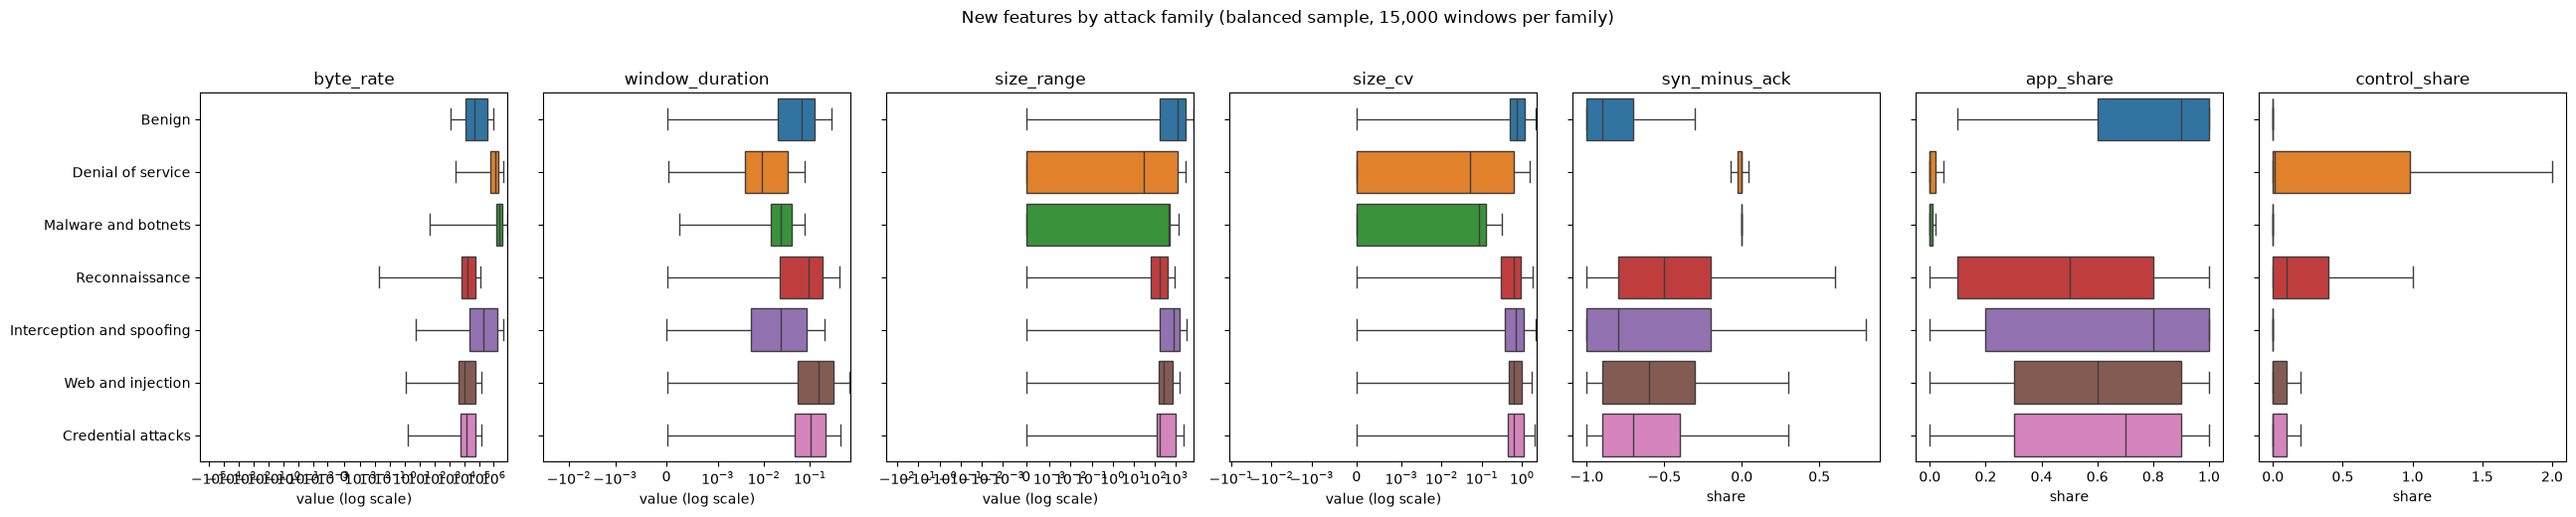

In [6]:
NEW_FEATS = TIME_FEATS + NUM_FEATS + DOMAIN_FEATS
fig, axes = plt.subplots(1, len(NEW_FEATS), figsize=(26, 5), sharey=True)
for ax, c in zip(axes, NEW_FEATS):
    sns.boxplot(x=df.loc[BAL, c], y=yb, order=FAMILY_ORDER, palette=PAL, ax=ax, showfliers=False)
    if c in TIME_FEATS + NUM_FEATS:
        ax.set_xscale("symlog", linthresh=1e-3)
    ax.set_title(c); ax.set_xlabel("value (log scale)" if c in TIME_FEATS + NUM_FEATS else "share"); ax.set_ylabel("")
plt.suptitle("New features by attack family (balanced sample, 15,000 windows per family)", y=1.03)
plt.tight_layout(); savefig("new_features_by_family")

In [7]:
PARENTS = {"byte_rate": ["Rate", "AVG"], "window_duration": ["IAT", "Number"], "size_range": ["Max", "Min"],
           "size_cv": ["Std", "AVG"], "syn_minus_ack": ["syn_flag_number", "ack_flag_number"],
           "app_share": ["HTTP", "HTTPS", "DNS"], "control_share": ["syn_flag_number", "rst_flag_number"]}
cols = list(dict.fromkeys(NEW_FEATS + [p for v in PARENTS.values() for p in v]))
Xs = df.loc[BAL, cols].astype("float64")
for c in Xs:                                           # MI is estimated with nearest neighbours: compare skewed columns on a log scale
    if c in CONT_RAW + TIME_FEATS + NUM_FEATS:
        Xs[c] = np.log1p(Xs[c])
mi = pd.Series(mutual_info_classif(Xs, yb, random_state=RANDOM_STATE, n_jobs=-1), index=cols)

def rank_biserial(x, y):
    a, b = x[y == 1], x[y == 0]
    return 2 * stats.mannwhitneyu(a, b, alternative="two-sided").statistic / (len(a) * len(b)) - 1

isat = df.loc[BAL, "is_attack"].to_numpy()
val = pd.DataFrame({"parents": [", ".join(PARENTS[c]) for c in NEW_FEATS],
                    "MI family (new)": mi[NEW_FEATS].values,
                    "best MI family (parent)": [mi[PARENTS[c]].max() for c in NEW_FEATS],
                    "rank-biserial r (attack vs benign)": [rank_biserial(df.loc[BAL, c].to_numpy(), isat) for c in NEW_FEATS]},
                   index=NEW_FEATS)
val["gain over best parent"] = val["MI family (new)"] - val["best MI family (parent)"]
val.to_csv(TABLE_DIR / "IoT23_fe_validation.csv")
val.round(3)

,parents,MI family (new),best MI family (parent),rank-biserial r (attack vs benign),gain over best parent
byte_rate,"Rate, AVG",0.416,0.802,0.128,-0.386
window_duration,"IAT, Number",0.246,0.607,-0.079,-0.362
size_range,"Max, Min",0.662,0.868,-0.341,-0.207
size_cv,"Std, AVG",0.517,0.802,-0.331,-0.285
syn_minus_ack,"syn_flag_number, ack_flag_number",0.579,0.523,0.538,0.056
app_share,"HTTP, HTTPS, DNS",0.473,0.391,-0.541,0.082
control_share,"syn_flag_number, rst_flag_number",0.316,0.234,0.200,0.081


**Interpretation.**
* **The three domain features add information:** their mutual information with the family is higher than that of any column they are built from — `syn_minus_ack` 0.579 vs 0.523 (+0.056), `app_share` 0.473 vs 0.391 (+0.082), `control_share` 0.316 vs 0.234 (+0.081). They also give the largest attack-vs-benign effects: `app_share` r = −0.541 and `syn_minus_ack` r = +0.538 (large; attacks use fewer application packets and fewer ACKs).
* **The time and size combinations carry less than their best parent:** `byte_rate` 0.416 vs 0.802 (`AVG`), `size_range` 0.662 vs 0.868, `size_cv` 0.517 vs 0.802, `window_duration` 0.246 vs 0.607. Their attack-vs-benign effects are medium for `size_range` (r = −0.341) and `size_cv` (−0.331), small for `byte_rate` (0.128) and `window_duration` (−0.079). They describe the traffic in a different way (throughput, uniformity) but do not replace the original columns.
* **Box plots:** every new feature separates the floods (DoS, Mirai) from Benign clearly, while reconnaissance, web, credential and spoofing overlap with Benign — the same picture as phase 4. All seven features stay candidates; §4 decides which are kept.

---
## 2 · Encoding (5.3)
CICIoT2023 has one categorical column, `Protocol_Type` (IP protocol number of the window). It is a **code, not a quantity**
(17 = UDP is not "more" than 6 = TCP), so it is **one-hot encoded**: one 0/1 column per protocol. Protocols seen fewer than 1,000 times are grouped into
`proto_other` (rare-category grouping), and an unseen protocol in new data would go there too.

The other columns need no encoding: the TCP flags and application protocols are already numeric shares of packets, and the dataset has no port column.

> **Note.** This project has no modelling phase, so every learned step is fitted on all the data. In a modelling phase, these steps must be refitted on the training part only, to avoid data leakage.

In [8]:
print("rows per protocol:", df["Protocol_Type"].map(PROTO_NAMES).value_counts().to_dict())
ohe = OneHotEncoder(min_frequency=1000, handle_unknown="infrequent_if_exist", sparse_output=False).fit(df[["Protocol_Type"]])
OHE_NAMES = [n.replace("Protocol_Type_infrequent_sklearn", "proto_other") for n in ohe.get_feature_names_out()]
OHE_NAMES = [f"proto_{PROTO_NAMES[int(n.split('_')[-1])]}" if n != "proto_other" else n for n in OHE_NAMES]
print("one-hot columns:", OHE_NAMES, "| grouped as rare:", [PROTO_NAMES[int(v)] for v in ohe.infrequent_categories_[0]])
OH = pd.DataFrame(ohe.transform(df[["Protocol_Type"]]), columns=OHE_NAMES, index=df.index).astype("int8")
ex = df[["Protocol_Type"]].drop_duplicates().sort_values("Protocol_Type")
pd.concat([ex["Protocol_Type"].map(PROTO_NAMES).rename("protocol"), OH.loc[ex.index]], axis=1).reset_index(drop=True)

rows per protocol: {'TCP': 2606598, 'UDP': 1011750, 'ICMP': 396984, 'GRE': 396306, 'nonIP': 9073, 'IGMP': 3}
one-hot columns: ['proto_nonIP', 'proto_ICMP', 'proto_TCP', 'proto_UDP', 'proto_GRE', 'proto_other'] | grouped as rare: ['IGMP']


,protocol,proto_nonIP,proto_ICMP,proto_TCP,proto_UDP,proto_GRE,proto_other
0,nonIP,1,0,0,0,0,0
1,ICMP,0,1,0,0,0,0
2,IGMP,0,0,0,0,0,1
3,TCP,0,0,1,0,0,0
4,UDP,0,0,0,1,0,0
5,GRE,0,0,0,0,1,0


---
## 3 · Scaling and transformation (5.6)
**Which columns.** Only the continuous and count columns (sizes, rates, times, counts and the new time / size features).
The 22 shares, the domain features and the one-hot columns are already on a small fixed range ([0, 1], [−1, 1] or [0, 3]) and keep their meaning
("60 % of the packets are SYN"), so they are left as they are.

**Transformation (shape).** Notebook 07 found extreme right skew. Rule per column, decided on a 500,000-row random sample:
* |skewness| ≤ 1 → no transformation;
* otherwise `log1p(x)` = log(1 + x) (simple, interpretable, defined at 0) if it brings |skewness| to ≤ 1 or does at least as well as Yeo-Johnson;
* otherwise **Yeo-Johnson**, a power transformation whose parameter λ is estimated from the data.

**Scaling (range).** `RobustScaler`: subtract the **median** and divide by the **IQR**. We use it instead of `StandardScaler` (mean and standard deviation)
because in this data the outliers *are* the attacks (notebook 05, 2.4): with the mean and standard deviation the flood windows would set the scale for everything else.
**Exception:** a column whose IQR is 0 (more than half of its values are equal) cannot be divided by its IQR — `RobustScaler` then leaves it unscaled
and it would dominate the PCA. Such columns are centred on the median and divided by their **standard deviation** instead (same rule as NetFlow).

> **Note.** This project has no modelling phase, so every learned step is fitted on all the data. In a modelling phase, these steps must be refitted on the training part only, to avoid data leakage.

In [9]:
CONT = CONT_RAW + TIME_FEATS + NUM_FEATS
BOUNDED = SHARES + DOMAIN_FEATS
assert (df[CONT] >= 0).all().all(), "log1p needs non-negative values"
fit_s = df.sample(500_000, random_state=RANDOM_STATE)

rows, TRANSFORM, PT = [], {}, {}
for c in CONT:
    x = fit_s[c].to_numpy("float64")
    s_raw, s_log = stats.skew(x), stats.skew(np.log1p(x))
    pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(x.reshape(-1, 1))
    xy = pt.transform(x.reshape(-1, 1)).ravel()
    s_yj = stats.skew(xy) if np.isfinite(xy).all() else np.inf
    if abs(s_raw) <= 1:
        t = "none"
    elif abs(s_log) <= 1 or abs(s_log) <= abs(s_yj):
        t = "log1p"
    else:
        t, PT[c] = "yeo-johnson", pt
    TRANSFORM[c] = t
    rows.append({"feature": c, "skew raw": s_raw, "skew log1p": s_log, "skew Yeo-Johnson": s_yj, "chosen": t,
                 "lambda (YJ)": pt.lambdas_[0] if t == "yeo-johnson" else np.nan})
skew_tab = pd.DataFrame(rows).set_index("feature")

T = pd.DataFrame({c: np.log1p(df[c].to_numpy("float64")) if TRANSFORM[c] == "log1p"
                  else PT[c].transform(df[[c]].to_numpy("float64")).ravel() if TRANSFORM[c] == "yeo-johnson"
                  else df[c].to_numpy("float64") for c in CONT}, index=df.index)
scaler = RobustScaler().fit(T)
# IQR = 0 (more than half of the values are equal): RobustScaler would silently leave the column unscaled (scale 1),
# so it would dominate distances and the PCA. Those columns are divided by their standard deviation instead (same rule as NetFlow).
q1, q3 = T.quantile(.25), T.quantile(.75)
IQR0 = [c for c in CONT if q3[c] - q1[c] == 0]
for c in IQR0:
    scaler.scale_[CONT.index(c)] = T[c].std() if T[c].std() > 0 else 1.0
print("IQR = 0 -> divided by the standard deviation instead:", IQR0 or "none")
X = pd.concat([pd.DataFrame(scaler.transform(T), columns=CONT, index=df.index), df[BOUNDED], OH], axis=1).astype("float32")
del T
skew_tab["skew after"] = [stats.skew(X.loc[fit_s.index, c]) for c in CONT]
skew_tab["median after"] = X[CONT].median().values
skew_tab["IQR after"] = (X[CONT].quantile(.75) - X[CONT].quantile(.25)).values
skew_tab["scale"] = ["std (IQR = 0)" if c in IQR0 else "IQR" for c in CONT]
skew_tab.to_csv(TABLE_DIR / "IoT23_fe_transform.csv")
print("chosen transformation:", pd.Series(TRANSFORM).value_counts().to_dict(), "| feature matrix:", X.shape)
skew_tab.round(2)

IQR = 0 -> divided by the standard deviation instead: ['fin_count', 'rst_count']


chosen transformation: {'yeo-johnson': 11, 'log1p': 8, 'none': 1} | feature matrix: (4420714, 51)


,skew raw,skew log1p,skew Yeo-Johnson,chosen,lambda (YJ),skew after,median after,IQR after,scale
feature,,,,,,,,,
Header_Length,0.16,-1.15,-0.31,none,NaN,0.16,0.0,1.0,IQR
Time_To_Live,3.55,1.90,-1.16,yeo-johnson,-0.29,-1.16,0.0,1.0,IQR
Rate,62.53,-0.63,-0.07,log1p,NaN,-0.63,0.0,1.0,IQR
ack_count,2.68,1.04,0.37,yeo-johnson,-0.48,0.37,0.0,1.0,IQR
syn_count,2.10,1.72,1.04,yeo-johnson,-0.96,1.04,0.0,1.0,IQR
fin_count,4.38,3.82,2.11,yeo-johnson,-2.89,2.11,0.0,0.0,std (IQR = 0)
rst_count,3.85,2.83,2.02,yeo-johnson,-2.20,2.02,0.0,0.0,std (IQR = 0)
Tot_sum,1.25,0.10,0.01,log1p,NaN,0.10,0.0,1.0,IQR
Min,4.89,2.68,1.01,yeo-johnson,-2.74,1.01,0.0,1.0,IQR


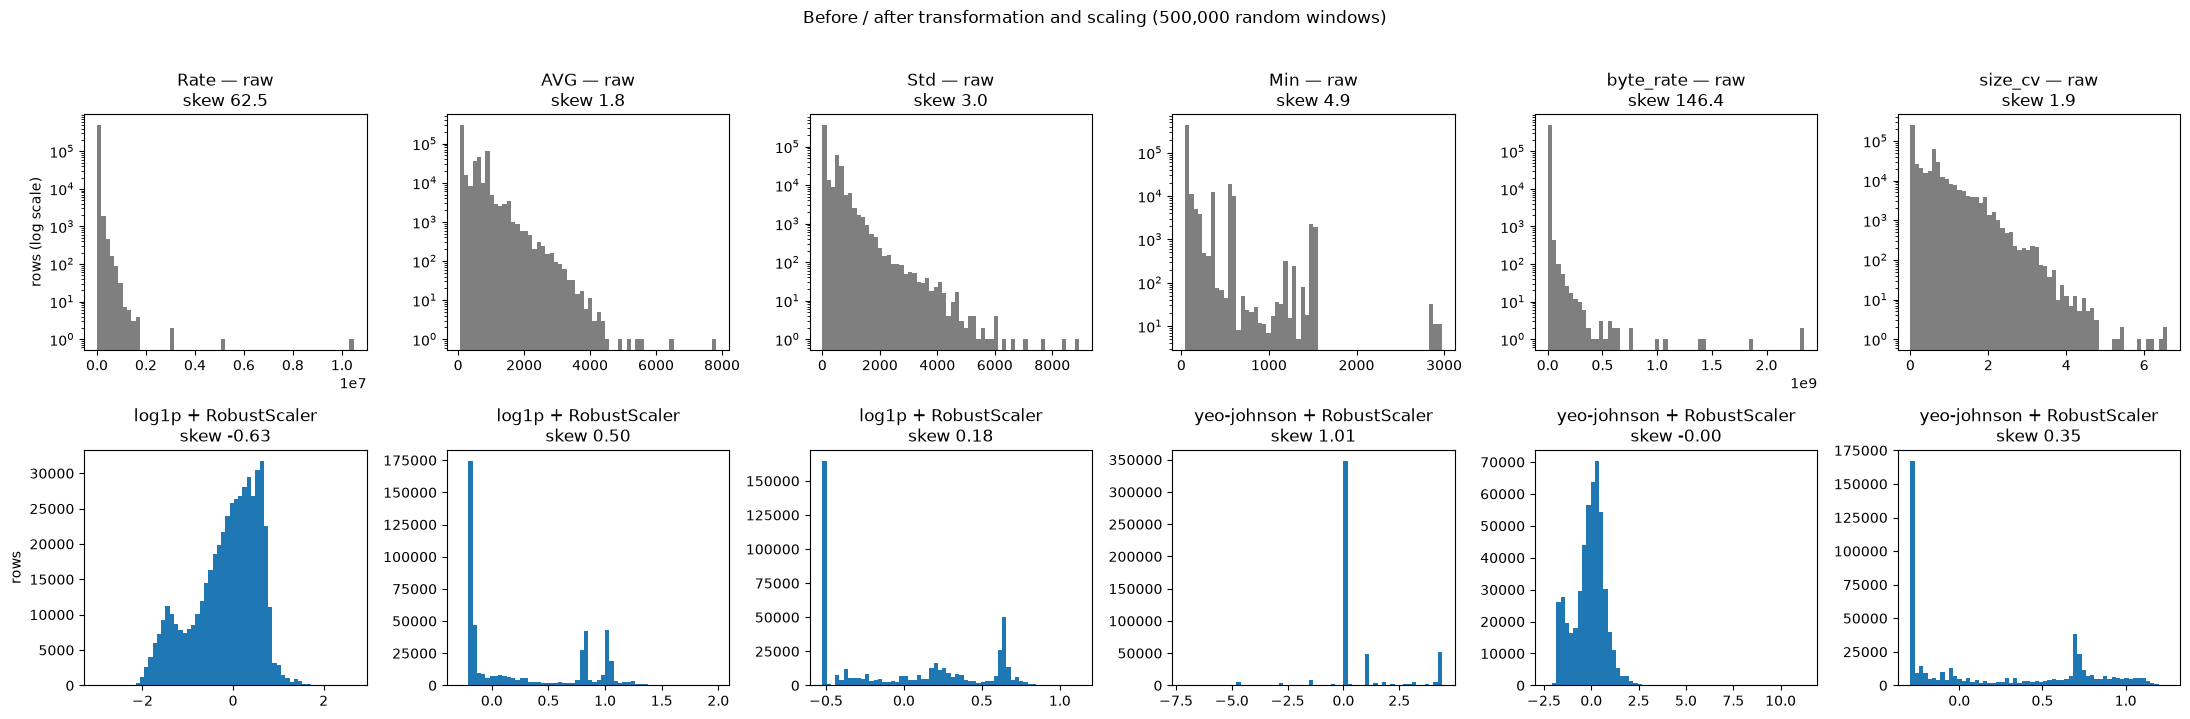

In [10]:
SHOW = ["Rate", "AVG", "Std", "Min", "byte_rate", "size_cv"]
fig, axes = plt.subplots(2, len(SHOW), figsize=(22, 7))
for j, c in enumerate(SHOW):
    axes[0, j].hist(fit_s[c].astype("float64"), bins=60, color="tab:gray"); axes[0, j].set_yscale("log")
    axes[0, j].set_title(f"{c} — raw\nskew {skew_tab.loc[c, 'skew raw']:.1f}")
    axes[1, j].hist(X.loc[fit_s.index, c], bins=60, color="tab:blue")
    axes[1, j].set_title(f"{TRANSFORM[c]} + RobustScaler\nskew {skew_tab.loc[c, 'skew after']:.2f}")
axes[0, 0].set_ylabel("rows (log scale)"); axes[1, 0].set_ylabel("rows")
plt.suptitle("Before / after transformation and scaling (500,000 random windows)", y=1.02)
plt.tight_layout(); savefig("before_after")

**Interpretation.**
* **Before:** 19 of the 20 continuous columns have |skewness| > 1, from 1.25 (`Tot_sum`) to 693.80 (`window_duration`); e.g. `Rate` 62.53, `byte_rate` 146.39, `IAT` 434.25. Only `Header_Length` (0.16) is left untransformed.
* **Chosen:** `log1p` for 8 columns (`Rate`, `Tot_sum`, `Max`, `AVG`, `Std`, `Tot_size`, `Variance`, `size_range`), Yeo-Johnson for 11 (`Time_To_Live`, the 4 counts, `Min`, `IAT`, `Number`, `byte_rate`, `window_duration`, `size_cv`).
* **After:** |skewness| ≤ 1.16 for every column except `IAT` (2.92), `fin_count` (2.11) and `rst_count` (2.02) — e.g. `Rate` 62.53 → −0.63 and `byte_rate` 146.39 → −0.00. These three are all removed in §4. Every column has median 0 after scaling, and IQR 1 except the two below.
* **IQR = 0:** `fin_count` and `rst_count` (more than half of the windows have no FIN / RST packet) were centred on the median and **divided by their standard deviation** instead; their IQR is still 0 after scaling because the middle half is one value. Both are removed later as artefacts, so the final features are all IQR-scaled.
* **Figure:** `Rate` and `byte_rate` change from one spike into a spread-out bell. `AVG`, `Std` and `size_cv` keep several peaks (one per traffic type, e.g. the 60-byte flood packets): a transformation removes skew but does not merge real groups. `Min` keeps a very narrow centre with values far out on both sides: its middle 50 % is so narrow that dividing by the IQR stretches it (this matters for the PCA in §6).

---
## 4 · Feature selection (5.8)
Five steps, each removal with a reason (same steps and thresholds as the NetFlow notebook):

1. **Exact copies** — columns that are a formula of other columns carry no new information.
2. **Artefacts** — columns that describe the *capture method* or the *lab machines*, not the attack behaviour (notebook 07, §6).
3. **Near-constant columns** — one value in ≥ 99.5 % of rows, *unless* the rare values are concentrated in one family (then they may be a rare-class signal).
4. **Correlated pairs** with |Spearman ρ| ≥ 0.95 — keep the column with the higher mutual information with the family.
5. **Mutual-information ranking** of the remaining features.

Steps 3–5 use the family-balanced sample, so that Denial of service (≈ 60 % of rows) does not decide what counts as "constant" or "informative".

> **Note.** This project has no modelling phase, so every learned step is fitted on all the data. In a modelling phase, these steps must be refitted on the training part only, to avoid data leakage.

In [11]:
s = df.loc[BAL]
ident = pd.DataFrame([
    ("Tot_size", "AVG", (s.Tot_size - s.AVG).abs().max()),
    ("Variance", "Std²", ((s.Variance - s.Std.astype("float64") ** 2).abs() / s.Variance.clip(lower=1)).max()),
    ("Tot_sum", "AVG × Number", ((s.Tot_sum - s.AVG.astype("float64") * s.Number).abs() / s.Tot_sum).max()),
    ("LLC", "IPv", (s.LLC - s.IPv).abs().max()),
    ("ARP", "1 − IPv", (s.ARP - (1 - s.IPv)).abs().max()),
] + [(c, f"{c.split('_')[0]}_flag_number × Number", (s[c] - (s[f"{c.split('_')[0]}_flag_number"] * s.Number).round()).abs().max())
     for c in COUNTS], columns=["column", "equals", "max difference"])
ident["identity holds"] = ident["max difference"] < 0.01
holds = ident.set_index("column")["identity holds"]
DROP_IDENTITY = {k: v for k, v, chk_col in [("Tot_size", "= AVG", "Tot_size"), ("Variance", "= Std²", "Variance"), ("LLC", "= IPv", "LLC"),
                                            ("IPv", "= 1 − ARP (ARP kept: names the non-IP share directly)", "ARP")] if holds[chk_col]}
if rho_rate_iat < -0.99:                                   # near-identity found in 1.1
    DROP_IDENTITY["IAT"] = (f"≈ 1 / Rate (Spearman rho = {rho_rate_iat:.3f}, median Rate × IAT = {prod.median():.3f}); "
                            "Rate kept: packets per second reads directly")
print("step 1 — dropped as copies:", list(DROP_IDENTITY))
ident

step 1 — dropped as copies: ['Tot_size', 'Variance', 'LLC', 'IPv', 'IAT']


,column,equals,max difference,identity holds
0,Tot_size,AVG,0.000000e+00,True
1,Variance,Std²,1.735882e-07,True
2,Tot_sum,AVG × Number,5.714011e-08,True
3,LLC,IPv,0.000000e+00,True
4,ARP,1 − IPv,2.980232e-08,True
5,ack_count,ack_flag_number × Number,0.000000e+00,True
6,syn_count,syn_flag_number × Number,0.000000e+00,True
7,fin_count,fin_flag_number × Number,0.000000e+00,True
8,rst_count,rst_flag_number × Number,0.000000e+00,True


In [12]:
DROP_ARTEFACT = {"Number": "packets per window: 10 for non-flood captures, 100 for floods (capture method)",
                 "Tot_sum": "= AVG × Number, inherits the Number artefact",
                 "window_duration": "= Number × IAT, inherits the Number artefact",
                 "Time_To_Live": "≈ 64 for every attacker, ≈ 99 for benign: identifies the lab machines' operating systems",
                 **{c: "= flag share × Number, inherits the Number artefact" for c in COUNTS if holds[c]}}
art = list(DROP_ARTEFACT)
mi_art = pd.Series(mutual_info_classif(X.loc[BAL, art], yb, random_state=RANDOM_STATE, n_jobs=-1), index=art)
art_tab = pd.DataFrame({"MI family": mi_art, "reason": pd.Series(DROP_ARTEFACT)})
art_tab["Benign median"] = s.loc[s.attack_family == BENIGN, art].median()
art_tab["attack median"] = s.loc[s.is_attack == 1, art].median()
print("step 2 — artefacts: high MI here is a warning sign, not a reason to keep them (shortcuts that do not exist on another network)")
art_tab.round(3)

step 2 — artefacts: high MI here is a warning sign, not a reason to keep them (shortcuts that do not exist on another network)


,MI family,reason,Benign median,attack median
Number,0.610,"packets per window: 10 for non-flood captures,...",10.000,10.000
Tot_sum,0.920,"= AVG × Number, inherits the Number artefact",2382.000,4718.000
window_duration,0.245,"= Number × IAT, inherits the Number artefact",0.066,0.041
Time_To_Live,0.553,"≈ 64 for every attacker, ≈ 99 for benign: iden...",99.400,67.000
ack_count,0.445,"= flag share × Number, inherits the Number art...",9.000,5.000
syn_count,0.144,"= flag share × Number, inherits the Number art...",0.000,0.000
fin_count,0.057,"= flag share × Number, inherits the Number art...",0.000,0.000
rst_count,0.089,"= flag share × Number, inherits the Number art...",0.000,0.000


In [13]:
cand = [c for c in X.columns if c not in DROP_IDENTITY and c not in DROP_ARTEFACT]
mode = X.loc[BAL, cand].mode().iloc[0]
top = (X.loc[BAL, cand] == mode).mean()
near = top[top >= 0.995].index
nz = X.loc[BAL, near] != mode[near]
nz_family = nz.groupby(yb).mean().T[FAMILY_ORDER]
near_tab = pd.concat([top[near].rename("top value share"), nz.mean().rename("other values share"), nz_family], axis=1)
near_tab["max lift"] = nz_family.max(axis=1) / nz.mean()
near_tab["family"] = nz_family.idxmax(axis=1)
near_tab["decision"] = np.where(near_tab["max lift"] >= 3, "keep (rare-class signal)", "drop")
DROP_NEAR = {c: f"one value in {100 * near_tab.loc[c, 'top value share']:.2f} % of rows, no family concentration"
             for c in near_tab.index[near_tab["decision"] == "drop"]}
near_tab.to_csv(TABLE_DIR / "IoT23_fe_near_constant.csv")
print("step 3 — dropped as near-constant:", list(DROP_NEAR))
near_tab.round(3)

step 3 — dropped as near-constant: ['ece_flag_number', 'cwr_flag_number', 'IRC', 'IGMP', 'proto_other']


,top value share,other values share,Benign,Denial of service,Malware and botnets,Reconnaissance,Interception and spoofing,Web and injection,Credential attacks,max lift,family,decision
ece_flag_number,0.997,0.003,0.003,0.003,0.001,0.001,0.006,0.003,0.007,2.031,Credential attacks,drop
cwr_flag_number,0.998,0.002,0.002,0.001,0.000,0.001,0.004,0.003,0.005,2.023,Credential attacks,drop
Telnet,1.000,0.000,0.000,0.002,0.000,0.002,0.000,0.000,0.000,3.690,Denial of service,keep (rare-class signal)
SMTP,0.999,0.001,0.000,0.002,0.000,0.002,0.000,0.000,0.000,3.610,Reconnaissance,keep (rare-class signal)
IRC,0.999,0.001,0.001,0.002,0.001,0.003,0.000,0.003,0.000,1.822,Reconnaissance,drop
IGMP,0.996,0.004,0.003,0.002,0.002,0.004,0.002,0.007,0.005,1.853,Web and injection,drop
proto_other,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,Benign,drop


In [14]:
cand2 = [c for c in cand if c not in DROP_NEAR]
mi_all = pd.Series(mutual_info_classif(X.loc[BAL, cand2], yb, random_state=RANDOM_STATE, n_jobs=-1), index=cand2)
rho = X.loc[BAL, cand2].corr(method="spearman")
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename("rho").reset_index()
pairs = pairs[pairs["rho"].abs() >= 0.95].assign(a=lambda p: p["rho"].abs()).sort_values("a", ascending=False)
DROP_CORR = {}
for _, p in pairs.iterrows():
    a, b = p["level_0"], p["level_1"]
    if a in DROP_CORR or b in DROP_CORR:
        continue
    lose, keep = (a, b) if mi_all[a] < mi_all[b] else (b, a)
    DROP_CORR[lose] = f"|rho| = {abs(p['rho']):.3f} with {keep}, lower MI ({mi_all[lose]:.3f} vs {mi_all[keep]:.3f})"
corr_tab = pairs.rename(columns={"level_0": "feature A", "level_1": "feature B"})[["feature A", "feature B", "rho"]]
corr_tab["MI A"], corr_tab["MI B"] = mi_all[corr_tab["feature A"]].values, mi_all[corr_tab["feature B"]].values
corr_tab["dropped"] = [a if a in DROP_CORR else b if b in DROP_CORR else "—" for a, b in zip(corr_tab["feature A"], corr_tab["feature B"])]
corr_tab.to_csv(TABLE_DIR / "IoT23_fe_correlated_pairs.csv", index=False)
print("step 4 — dropped as correlated:", list(DROP_CORR))
corr_tab.round(3)

step 4 — dropped as correlated: ['ack_flag_number', 'Std']


,feature A,feature B,rho,MI A,MI B,dropped
454,ack_flag_number,syn_minus_ack,-0.966,0.522,0.580,ack_flag_number
172,Std,size_range,0.966,0.534,0.662,Std


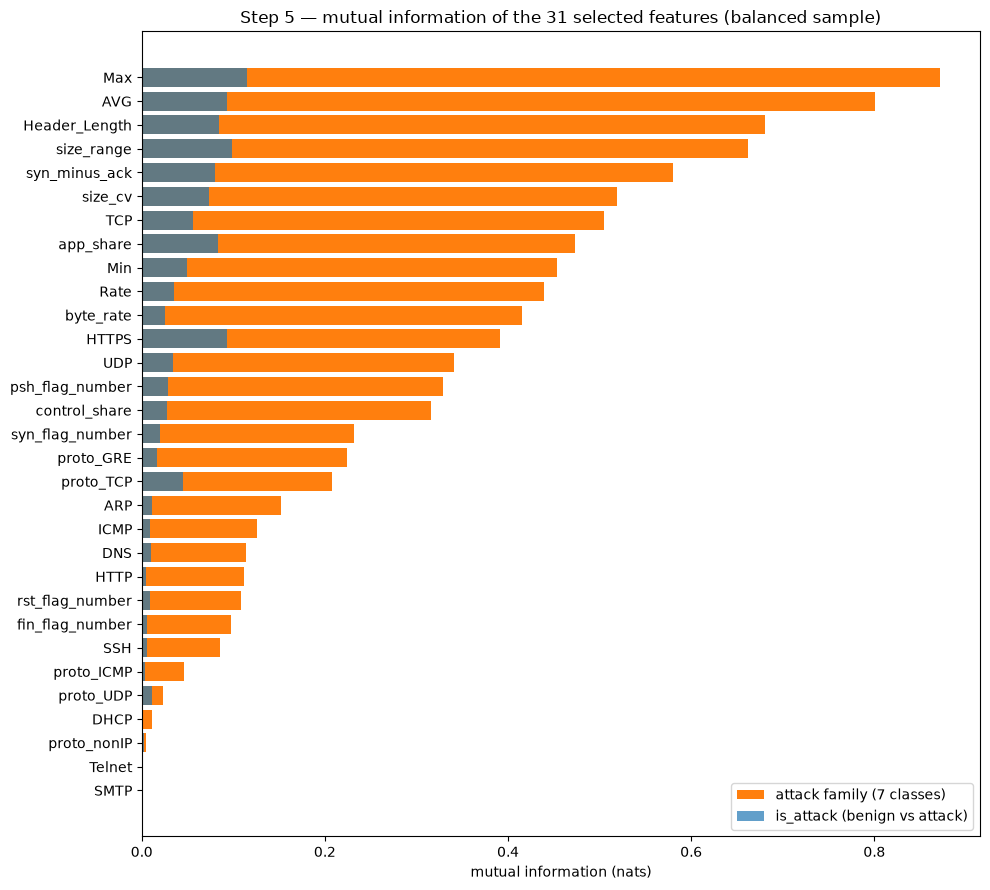

,MI family,MI is_attack,rank
Max,0.872,0.115,1
AVG,0.801,0.093,2
Header_Length,0.680,0.084,3
size_range,0.662,0.099,4
syn_minus_ack,0.580,0.080,5
size_cv,0.519,0.074,6
TCP,0.504,0.056,7
app_share,0.473,0.084,8
Min,0.453,0.049,9
Rate,0.439,0.036,10


In [15]:
FINAL = [c for c in cand2 if c not in DROP_CORR]
mi_att = pd.Series(mutual_info_classif(X.loc[BAL, FINAL], df.loc[BAL, "is_attack"], random_state=RANDOM_STATE, n_jobs=-1), index=FINAL)
rank = pd.DataFrame({"MI family": mi_all[FINAL], "MI is_attack": mi_att}).sort_values("MI family", ascending=False)
rank["rank"] = range(1, len(rank) + 1)
rank.to_csv(TABLE_DIR / "IoT23_fe_mi_ranking.csv")

fig, ax = plt.subplots(figsize=(10, 9))
r = rank.iloc[::-1]
ax.barh(r.index, r["MI family"], color="tab:orange", label="attack family (7 classes)")
ax.barh(r.index, r["MI is_attack"], color="tab:blue", alpha=.7, label="is_attack (benign vs attack)")
ax.set_xlabel("mutual information (nats)"); ax.legend(loc="lower right")
ax.set_title(f"Step 5 — mutual information of the {len(FINAL)} selected features (balanced sample)")
plt.tight_layout(); savefig("mi_ranking")
rank.round(3)

**Interpretation.** 51 candidates (39 original + 7 created + 6 one-hot − the protocol code) → **31 features**.
1. **Copies (5):** every identity holds exactly (maximum difference < 2 × 10⁻⁷). `Tot_size` = `AVG`, `Variance` = `Std`², `LLC` = `IPv`, `IPv` = 1 − `ARP`, and `IAT` ≈ 1 / `Rate` (ρ = −0.995). `Tot_sum` = `AVG` × `Number` and the 4 counts = flag share × `Number` also hold; they are removed in step 2.
2. **Artefacts (8):** `Number`, `Tot_sum`, `window_duration`, `Time_To_Live` and the 4 counts. Their mutual information is high — `Tot_sum` 0.920 (higher than any kept feature), `Number` 0.610, `Time_To_Live` 0.553 (benign median 99.4 vs attack 67.0) — and that is exactly the danger: they describe the capture method and the lab machines, which would not carry over to another network (SQ2).
3. **Near-constant (5):** `ece_flag_number`, `cwr_flag_number`, `IRC`, `IGMP` and `proto_other` (one value in 99.64–100 % of rows). `Telnet` and `SMTP` are also near-constant but kept by the rule, because their rare non-zero values are concentrated in one family (lift 3.69 in Denial of service and 3.61 in Reconnaissance); their mutual information is ≈ 0 (0.002 and 0.000), so they add little.
4. **Correlated (2):** two pairs with |ρ| = 0.966. `ack_flag_number` is dropped for `syn_minus_ack` (MI 0.522 vs 0.580) and `Std` for `size_range` (0.534 vs 0.662): in both pairs a created feature replaces an original one.
5. **Ranking:** the packet-size features lead — `Max` 0.872, `AVG` 0.801, `Header_Length` 0.680, `size_range` 0.662 — followed by `syn_minus_ack` 0.580 and `size_cv` 0.519. 4 of the top 8 features were created in §1. Mutual information with `is_attack` is at most 0.115 (`Max`): as in phase 4, telling *which* family is much easier than separating the quiet attacks from benign traffic.

---
## 5 · Final feature set (5.9)

In [16]:
summary = pd.DataFrame([(c, "1 copy", r) for c, r in DROP_IDENTITY.items()] + [(c, "2 artefact", r) for c, r in DROP_ARTEFACT.items()] +
                       [(c, "3 near-constant", r) for c, r in DROP_NEAR.items()] + [(c, "4 correlated", r) for c, r in DROP_CORR.items()],
                       columns=["feature", "step", "reason"])
summary.to_csv(TABLE_DIR / "IoT23_fe_dropped.csv", index=False)
print(f"{len(RAW_FEATURES)} original features + {len(NEW_FEATS)} created + {len(OHE_NAMES)} one-hot − 1 protocol code "
      f"= {X.shape[1]} candidates → {len(summary)} removed → {len(FINAL)} in the final set")
summary

39 original features + 7 created + 6 one-hot − 1 protocol code = 51 candidates → 20 removed → 31 in the final set


,feature,step,reason
0,Tot_size,1 copy,= AVG
1,Variance,1 copy,= Std²
2,LLC,1 copy,= IPv
3,IPv,1 copy,= 1 − ARP (ARP kept: names the non-IP share di...
4,IAT,1 copy,"≈ 1 / Rate (Spearman rho = -0.995, median Rate..."
5,Number,2 artefact,"packets per window: 10 for non-flood captures,..."
6,Tot_sum,2 artefact,"= AVG × Number, inherits the Number artefact"
7,window_duration,2 artefact,"= Number × IAT, inherits the Number artefact"
8,Time_To_Live,2 artefact,"≈ 64 for every attacker, ≈ 99 for benign: iden..."
9,ack_count,2 artefact,"= flag share × Number, inherits the Number art..."


In [17]:
MEANING = {
    "Header_Length": "mean header length of the packets (bytes)", "Rate": "packets per second", "Min": "smallest packet (bytes)",
    "Max": "largest packet (bytes)", "AVG": "mean packet size (bytes)", "Std": "standard deviation of packet size (bytes)",
    "byte_rate": "bytes per second", "size_range": "largest − smallest packet (bytes)", "size_cv": "relative spread of packet sizes",
    "syn_minus_ack": "SYN share − ACK share: half-open handshakes", "app_share": "share of packets from a known application",
    "control_share": "SYN + FIN + RST shares: connection control packets", "ARP": "share of non-IP (ARP) packets",
    "TCP": "share of TCP packets", "UDP": "share of UDP packets", "ICMP": "share of ICMP packets", "DHCP": "share of DHCP packets",
    "IGMP": "share of IGMP packets", "Time_To_Live": "mean IP time-to-live", "IAT": "mean time between packets (s)",
    "Number": "packets in the window", "Tot_sum": "total bytes in the window", "Tot_size": "mean packet size (bytes)",
    "Variance": "variance of packet size", "window_duration": "time spanned by the window (s)",
    **{c: f"packets with the {c.split('_')[0].upper()} flag in the window" for c in COUNTS}, "IPv": "share of IP packets", "LLC": "share of LLC frames",
    **{f: f"share of packets with the {f.split('_')[0].upper()} flag" for f in FLAGS},
    **{a: f"share of {a} packets" for a in APP}, **{n: f"1 if the window's protocol is {n.split('_')[1]}" for n in OHE_NAMES}}
FORMULA = {"byte_rate": "AVG × Rate", "window_duration": "Number × IAT", "size_range": "Max − Min", "size_cv": "Std / AVG",
           "syn_minus_ack": "syn_flag_number − ack_flag_number", "app_share": "HTTP + HTTPS + DNS + Telnet + SMTP + SSH + IRC",
           "control_share": "syn + fin + rst flag shares", **{n: "one-hot of Protocol_Type" for n in OHE_NAMES}}
dropped = summary.set_index("feature")
dictionary = pd.DataFrame([{
    "feature": c,
    "origin": "original" if c in RAW_FEATURES else "one-hot" if c in OHE_NAMES else "created",
    "meaning": MEANING.get(c, ""),
    "formula": FORMULA.get(c, ""),
    "transformation": TRANSFORM.get(c, "none"),
    "scaling": ("median / std (IQR = 0)" if c in IQR0 else "RobustScaler (median / IQR)") if c in CONT else "none",
    "in final set": c in FINAL,
    "MI family": round(mi_all[c], 3) if c in mi_all.index else np.nan,
    "reason if removed": dropped.loc[c, "reason"] if c in dropped.index else "",
} for c in X.columns])
dictionary.to_csv(TABLE_DIR / "IoT23_fe_dictionary.csv", index=False)
dictionary[dictionary["in final set"]].drop(columns=["in final set", "reason if removed"]).sort_values("MI family", ascending=False).reset_index(drop=True)

,feature,origin,meaning,formula,transformation,scaling,MI family
0,Max,original,largest packet (bytes),,log1p,RobustScaler (median / IQR),0.872
1,AVG,original,mean packet size (bytes),,log1p,RobustScaler (median / IQR),0.801
2,Header_Length,original,mean header length of the packets (bytes),,none,RobustScaler (median / IQR),0.680
3,size_range,created,largest − smallest packet (bytes),Max − Min,log1p,RobustScaler (median / IQR),0.662
4,syn_minus_ack,created,SYN share − ACK share: half-open handshakes,syn_flag_number − ack_flag_number,none,none,0.580
5,size_cv,created,relative spread of packet sizes,Std / AVG,yeo-johnson,RobustScaler (median / IQR),0.519
6,TCP,original,share of TCP packets,,none,none,0.504
7,app_share,created,share of packets from a known application,HTTP + HTTPS + DNS + Telnet + SMTP + SSH + IRC,none,none,0.473
8,Min,original,smallest packet (bytes),,yeo-johnson,RobustScaler (median / IQR),0.453
9,Rate,original,packets per second,,log1p,RobustScaler (median / IQR),0.439


In [18]:
KEEP_LABELS = ["attack_label", "attack_family", "is_attack", "conflicting_features"]
final_df = pd.concat([X[FINAL], df[KEEP_LABELS]], axis=1)
path = PROCESSED_DIR / f"{SOURCE}_features.parquet"
final_df.to_parquet(path, index=False)
print(f"saved {path.name}: {final_df.shape[0]:,} rows × {len(FINAL)} features + {len(KEEP_LABELS)} label columns | "
      f"NaN: {int(final_df.isna().sum().sum())} | inf: {int(np.isinf(final_df[FINAL]).sum().sum())}")

saved IoT23_features.parquet: 4,420,714 rows × 31 features + 4 label columns | NaN: 0 | inf: 0


**How to use the exported files**

* `data/processed/IoT23_features.parquet`: one row per window, the final features (**already transformed and scaled**) and the label columns
  `attack_label` (34 labels), `attack_family` (7 families), `is_attack` (0/1) and `conflicting_features`.
* `tables/IoT23_fe_dictionary.csv`: every candidate feature with its meaning, formula, transformation, scaling, mutual information and, if removed, why.
* Rows with `conflicting_features = True` have the same features as a row with another label (mostly DoS vs DDoS, see the decision log):
  filter them with `df[~df["conflicting_features"]]` whenever the label matters.
* The original (unscaled) values stay in `IoT23_clean.parquet`; the created features can be recomputed from the formulas in the dictionary.

---
## 6 · PCA — a 2-D view of family separability (5.10)
PCA is a **feature extraction** method: it builds new uncorrelated components as weighted sums of the features, ordered by the variance they explain.
It is fitted on the family-balanced sample of the final features (already scaled, so no feature dominates because of its unit).

> **Note.** This project has no modelling phase, so every learned step is fitted on all the data. In a modelling phase, these steps must be refitted on the training part only, to avoid data leakage.

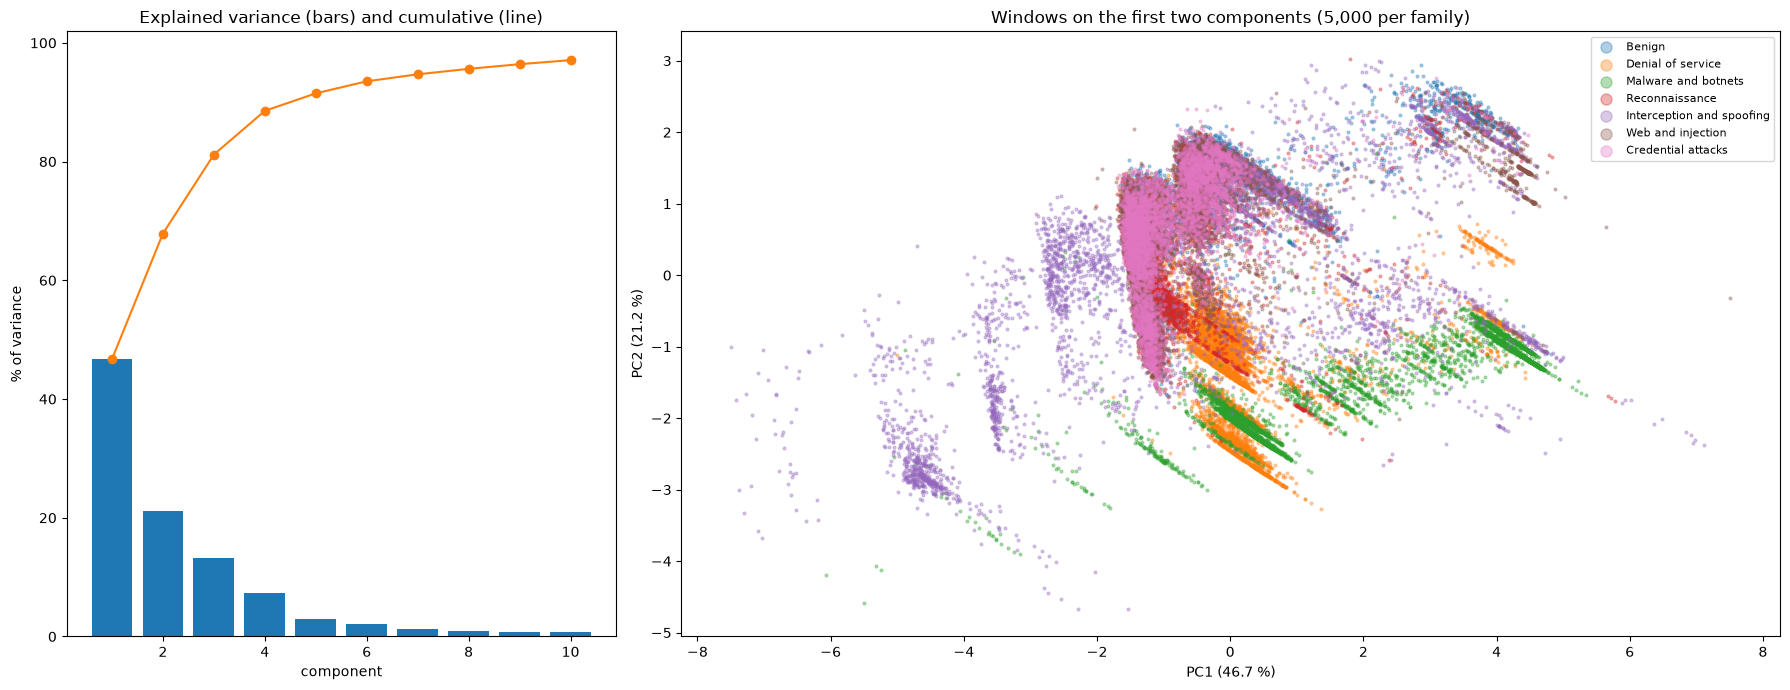

PC1 + PC2 explain 67.9 % of the variance; 10 components: 97.1 %; components for 90 %: 5


,PC1 feature,PC1 loading,PC2 feature,PC2 loading
0,Min,0.836,Header_Length,0.601
1,byte_rate,0.422,Min,0.322
2,Rate,0.249,syn_minus_ack,-0.289
3,AVG,0.133,proto_TCP,0.277
4,size_cv,-0.118,app_share,0.253
5,Header_Length,-0.099,Rate,-0.244


In [19]:
P_idx = np.concatenate([g.sample(min(len(g), 5_000), random_state=RANDOM_STATE).index
                        for _, g in df.loc[BAL].groupby("attack_family")])
pca = PCA(n_components=10, random_state=RANDOM_STATE).fit(X.loc[P_idx, FINAL])
Z = pca.transform(X.loc[P_idx, FINAL])
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(range(1, 11), 100 * ev, color="tab:blue"); ax[0].plot(range(1, 11), 100 * ev.cumsum(), "o-", color="tab:orange")
ax[0].set_xlabel("component"); ax[0].set_ylabel("% of variance"); ax[0].set_title("Explained variance (bars) and cumulative (line)")
fams = df.loc[P_idx, "attack_family"].to_numpy()
for f in FAMILY_ORDER:
    m = fams == f
    ax[1].scatter(Z[m, 0], Z[m, 1], s=4, alpha=.35, color=PAL[f], label=f)
ax[1].set_xlabel(f"PC1 ({100 * ev[0]:.1f} %)"); ax[1].set_ylabel(f"PC2 ({100 * ev[1]:.1f} %)")
ax[1].legend(markerscale=4, fontsize=8); ax[1].set_title("Windows on the first two components (5,000 per family)")
plt.tight_layout(); savefig("pca")
load = pd.DataFrame(pca.components_[:2].T, index=FINAL, columns=["PC1", "PC2"])
print(f"PC1 + PC2 explain {100 * ev[:2].sum():.1f} % of the variance; 10 components: {100 * ev.sum():.1f} %; "
      f"components for 90 %: {int(np.searchsorted(ev.cumsum(), .90) + 1) if ev.sum() >= .90 else '> 10'}")
top_load = {}
for pc in ["PC1", "PC2"]:
    t = load[pc].reindex(load[pc].abs().sort_values(ascending=False).index).head(6)
    top_load[f"{pc} feature"], top_load[f"{pc} loading"] = t.index.to_list(), t.round(3).to_list()
pd.DataFrame(top_load)

**Interpretation.** The first two components explain **67.9 %** of the variance (PC1 46.7 %, PC2 21.2 %); 5 components reach 90 % and 10 reach 97.1 %. The 31 features are therefore highly redundant, and most of the structure fits in a few dimensions.
* **PC1 ≈ "smallest packet and throughput":** `Min` (loading 0.836), `byte_rate` (0.422), `Rate` (0.249).
* **PC2 ≈ "normal TCP application traffic vs fast traffic without handshake":** `Header_Length` (0.601), `Min` (0.322), `proto_TCP` (0.277) and `app_share` (0.253) on the positive side; `syn_minus_ack` (−0.289) and `Rate` (−0.244) on the negative side.
* **What separates:** Benign, web, credential and most spoofing windows lie in the upper band (PC2 > 0); Denial of service and Mirai lie below (PC2 < 0) in separate diagonal stripes, and Mirai extends to high PC1 (large packets, high throughput). **What overlaps:** credential attacks lie on top of benign and web traffic, and reconnaissance overlaps Denial of service near the centre. Interception and spoofing is the most spread out family along PC1.
* **Caveat:** PCA weights each feature by its variance. `Min` dominates PC1 partly because robust scaling stretches it (§3), so this view depends on the scaling choice.

---
## 7 · Techniques not used and why

| Technique | Why not |
|---|---|
| Hour of day / date features | CICIoT2023 has no timestamps; they would only reveal the lab's attack schedule anyway |
| Polynomial features | the attack patterns are thresholds on single features (notebook 07, §6), not curved relationships; ≈ 900 extra columns at degree 2 |
| Binning of rates or sizes | it would throw away detail that the log transform keeps |
| Frequency / target encoding | no port or high-cardinality column; target encoding uses the label to build a feature (leakage risk) |
| Traffic asymmetry, burstiness | no packet direction and no spread of inter-arrival times in this dataset |
| `StandardScaler` / min-max scaling | dominated by the extreme values, which are the attacks themselves; RobustScaler is used instead |
| Train/test split, model-based importance | no modelling in this project (mutual information ranks the features instead) |

---
## 8 · Summary

| Step | Result |
|---|---|
| Creation | 7 new features: 2 time (`byte_rate`, `window_duration`), 2 packet-size (`size_range`, `size_cv`), 3 domain (`syn_minus_ack`, `app_share`, `control_share`) |
| Encoding | `Protocol_Type` → 6 one-hot columns; IGMP (3 windows) grouped as `proto_other` |
| Transformation | `log1p` for 8 columns, Yeo-Johnson for 11, none for 1; e.g. `Rate` skewness 62.53 → −0.63 |
| Scaling | RobustScaler; `fin_count` and `rst_count` (IQR = 0) divided by their standard deviation |
| Selection | 51 candidates − 5 copies − 8 artefacts − 5 near-constant − 2 correlated = **31 features** |
| Export | `IoT23_features.parquet`: 4,420,714 rows × 31 features + 4 label columns, no NaN or inf |
| PCA | 2 components explain 67.9 %, 5 components 90 % |

**Conclusions**
1. **Domain knowledge pays off:** `syn_minus_ack`, `app_share` and `control_share` carry more information about the family than the columns they are built from, and give the largest attack-vs-benign effects (\|r\| ≈ 0.54). Two of them replaced original columns in selection.
2. **Packet size is still the most informative group:** `Max` (0.872), `AVG` (0.801), `Header_Length` (0.680) and `size_range` (0.662) top the mutual-information ranking (SQ1).
3. **The strongest raw signals were artefacts and were removed:** `Tot_sum` (MI 0.920), `Number` (0.610) and `Time_To_Live` (0.553). The final set describes traffic behaviour rather than the capture set-up, which is what a comparison across networks (SQ2) needs.

Before modelling, split the data first and refit the learned steps on the training part only.